### 1 — Imports and project configuration

In [10]:
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow import keras

CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (path / "config" / "settings.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError("Could not find config/settings.py.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings

keras.utils.set_random_seed(settings.RANDOM_STATE)

print("Project:", settings.PROJECT_NAME)
print("Root:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Project: BrainScan_AI
Root: /home/moali/projects/brainscan_ai
TensorFlow: 2.21.0
GPU devices: []


### 2 — Define paths and training parameters

In [11]:
MODEL_DIR = settings.CLASSIFICATION_MODELS_DIR
REPORTS_DIR = settings.REPORTS_DIR
FIGURES_DIR = settings.FIGURES_DIR
METRICS_DIR = settings.METRICS_DIR

for directory in [MODEL_DIR, REPORTS_DIR, FIGURES_DIR, METRICS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "inceptionv3_initial.keras"
CLASS_MAPPING_PATH = MODEL_DIR / "inceptionv3_class_mapping.json"

BEST_HEAD_MODEL_PATH = MODEL_DIR / "inceptionv3_best_head.keras"
BEST_FINETUNED_MODEL_PATH = MODEL_DIR / "inceptionv3_best_finetuned.keras"
FINAL_MODEL_PATH = MODEL_DIR / "inceptionv3_final.keras"

HISTORY_PATH = METRICS_DIR / "inceptionv3_training_history.csv"

IMAGE_SIZE = 299
IMAGE_CHANNELS = 3
INPUT_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, IMAGE_CHANNELS)

BATCH_SIZE = settings.BATCH_SIZE
HEAD_EPOCHS = settings.EPOCHS
FINETUNE_EPOCHS = 10

HEAD_LEARNING_RATE = settings.LEARNING_RATE
FINETUNE_LEARNING_RATE = 1e-5

print("Model:", MODEL_PATH)
print("Batch size:", BATCH_SIZE)
print("Head training epochs:", HEAD_EPOCHS)
print("Fine-tuning epochs:", FINETUNE_EPOCHS)

Model: /home/moali/projects/brainscan_ai/models/classification/inceptionv3_initial.keras
Batch size: 32
Head training epochs: 30
Fine-tuning epochs: 10


### 3 — Load class mapping and manifests

In [12]:
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}. Run Notebook 04 first."
    )

if not CLASS_MAPPING_PATH.is_file():
    raise FileNotFoundError(
        f"Class mapping not found: {CLASS_MAPPING_PATH}. "
        "Run Notebook 04 first."
    )

with open(CLASS_MAPPING_PATH, encoding="utf-8") as file:
    class_config = json.load(file)

CLASS_NAMES = class_config["classes"]
LABEL_TO_ID = {
    str(label): int(index)
    for label, index in class_config["label_to_id"].items()
}
NUM_CLASSES = len(CLASS_NAMES)

train_df = pd.read_csv(settings.TRAIN_MANIFEST_PATH)
validation_df = pd.read_csv(settings.VALIDATION_MANIFEST_PATH)

# Adjust these names if Notebook 01 created different column names.
IMAGE_PATH_COL = "image_path"
LABEL_COL = "label"

required_columns = {IMAGE_PATH_COL, LABEL_COL}

for name, df in [
    ("train", train_df),
    ("validation", validation_df),
]:
    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} manifest is missing {missing}. "
            f"Available columns: {df.columns.tolist()}"
        )

print("Classes:", CLASS_NAMES)
print("Class mapping:", LABEL_TO_ID)
print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Training samples: 4916
Validation samples: 1053


### 4 — Validate image paths and labels

In [13]:
def resolve_image_path(value):
    path = Path(str(value)).expanduser()

    if not path.is_absolute():
        path = PROJECT_ROOT / path

    return path.resolve()


def prepare_manifest(df, name):
    df = df.copy()

    if df[IMAGE_PATH_COL].isna().any():
        raise ValueError(f"{name} manifest contains missing image paths.")

    if df[LABEL_COL].isna().any():
        raise ValueError(f"{name} manifest contains missing labels.")

    df["resolved_image_path"] = df[IMAGE_PATH_COL].map(
        resolve_image_path
    )

    missing_paths = [
        str(path)
        for path in df["resolved_image_path"]
        if not path.is_file()
    ]

    if missing_paths:
        raise FileNotFoundError(
            f"{name}: {len(missing_paths)} image files are missing. "
            f"Examples: {missing_paths[:5]}"
        )

    df["label_name"] = df[LABEL_COL].astype(str)

    unknown_labels = (
        set(df["label_name"].unique()) - set(LABEL_TO_ID)
    )

    if unknown_labels:
        raise ValueError(
            f"{name} manifest has unknown labels: {unknown_labels}"
        )

    df["label_id"] = df["label_name"].map(LABEL_TO_ID).astype("int32")

    return df


train_df = prepare_manifest(train_df, "Training")
validation_df = prepare_manifest(validation_df, "Validation")

print("All manifest image paths and labels are valid.")
display(train_df[[IMAGE_PATH_COL, "label_name", "label_id"]].head())

All manifest image paths and labels are valid.


,image_path,label_name,label_id
0,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma,0
1,/home/moali/projects/brainscan_ai/data/raw/not...,notumor,2
2,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma,1
3,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma,0
4,/home/moali/projects/brainscan_ai/data/raw/pit...,pituitary,3


### 5 — Build the TensorFlow data pipelines
InceptionV3 preprocessing expects RGB pixel values in the [0, 255] range before its preprocessing function transforms them. We will resize images to 299 × 299, and apply the same deterministic preprocessing to both datasets.

We will not augment validation images. For MRI classification, flips or other transformations should only be introduced after confirming they preserve the medically relevant label and image orientation.

In [14]:
AUTOTUNE = tf.data.AUTOTUNE


def load_and_preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        antialias=True,
    )

    image = tf.cast(image, tf.float32)

    image = keras.applications.inception_v3.preprocess_input(image)

    return image, label


def create_dataset(df, training=False):
    paths = df["resolved_image_path"].astype(str).to_numpy()
    labels = df["label_id"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=settings.RANDOM_STATE,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
validation_ds = create_dataset(validation_df, training=False)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_ds).numpy())

Training batches: 154
Validation batches: 33


### 6 — Inspect a training batch

Image batch shape: (32, 299, 299, 3)
Label batch shape: (32,)
Image value range: -1.0 to 1.0000004768371582


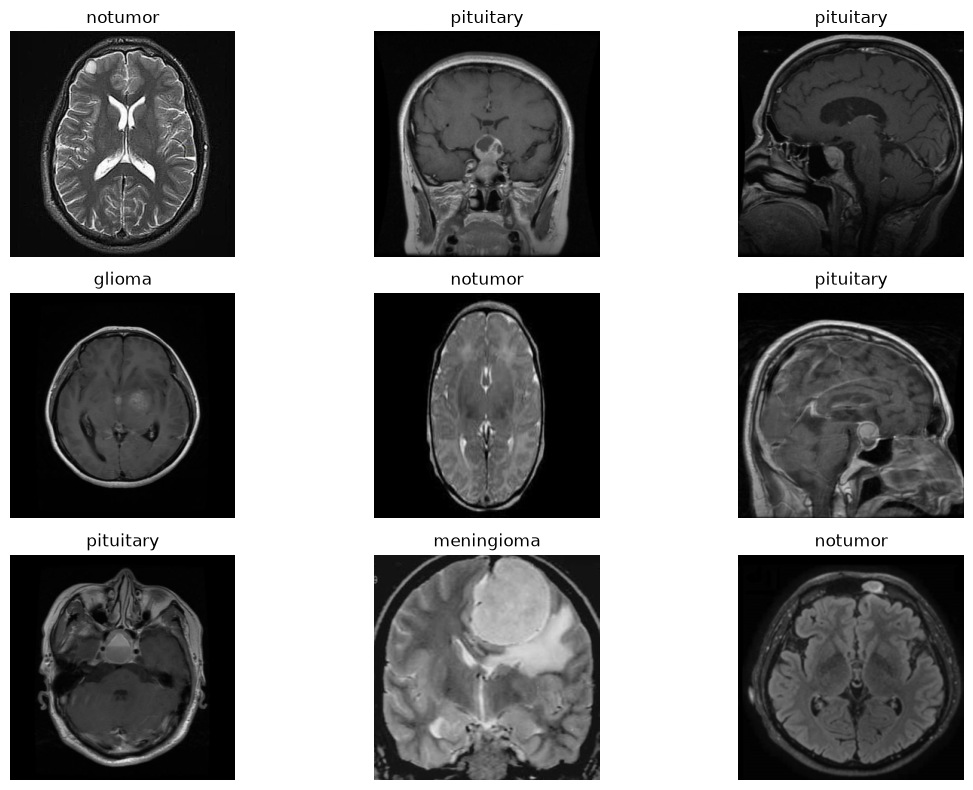

In [15]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image value range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

# Display images after reversing InceptionV3 preprocessing.
# This is for visualization only; training uses the preprocessed tensors.
plt.figure(figsize=(12, 8))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)

    image = images[i].numpy()
    image = (image + 1.0) * 127.5
    image = np.clip(image / 255.0, 0.0, 1.0)

    plt.imshow(image)
    plt.title(CLASS_NAMES[int(labels[i].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

### 7 — Load and compile InceptionV3

In [16]:
model = keras.models.load_model(
    MODEL_PATH,
    compile=False,
)

if model.output_shape[-1] != NUM_CLASSES:
    raise ValueError(
        f"Model outputs {model.output_shape[-1]} classes, "
        f"but the mapping defines {NUM_CLASSES}."
    )

backbone = model.get_layer("inception_v3")
backbone.trainable = False


def compile_classifier(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        ],
    )


compile_classifier(model, HEAD_LEARNING_RATE)

print("Loaded model:", model.name)
print("Backbone trainable:", backbone.trainable)
print("Total parameters:", f"{model.count_params():,}")
print(
    "Trainable parameters:",
    f"{sum(np.prod(v.shape) for v in model.trainable_variables):,}",
)

Loaded model: BrainScan_InceptionV3
Backbone trainable: False
Total parameters: 21,810,980
Trainable parameters: 8,196


### 8 — Configure callbacks

In [17]:
def     make_callbacks(checkpoint_path):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            mode="min",
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7,
            mode="min",
            verbose=1,
        ),
    ]

### 9 — Train the classification head

In [18]:
head_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=HEAD_EPOCHS,
    callbacks=make_callbacks(BEST_HEAD_MODEL_PATH),
    verbose=1,
)

head_history_df = pd.DataFrame(head_history.history)
head_history_df["phase"] = "frozen_backbone"
head_history_df["epoch"] = np.arange(1, len(head_history_df) + 1)

print("Head training completed.")                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

Epoch 1/30


/home/moali/projects/brainscan_ai/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 852ms/step - accuracy: 0.5795 - loss: 0.9720
Epoch 1: val_loss improved from None to 0.77986, saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_head.keras

Epoch 1: finished saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_head.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.5795 - loss: 0.9720 - val_accuracy: 0.6866 - val_loss: 0.7799 - learning_rate: 0.0010
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 846ms/step - accuracy: 0.6821 - loss: 0.7632
Epoch 2: val_loss improved from 0.77986 to 0.70407, saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_head.keras

Epoch 2: finished saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_head.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - accuracy: 0.6821 - loss: 0.7632 - val_accuracy: 0.7236 - val_loss: 0.7041 - learning_rate: 0.0010
Epoch 3/30
1

### 10 — Fine-tune the deeper layers
After training the classification head, we can allow the last 40 layers of InceptionV3 to adapt to MRI images. We will keep Batch Normalization layers frozen to reduce instability during fine-tuning.

In [20]:
# Start from the best head-training checkpoint.
if BEST_HEAD_MODEL_PATH.is_file():
    model = keras.models.load_model(
        BEST_HEAD_MODEL_PATH,
        compile=False,
    )

backbone = model.get_layer("inception_v3")
backbone.trainable = True

# Freeze earlier layers; fine-tune only the deeper layers.
for layer in backbone.layers[:-40]:
    layer.trainable = False

# Keep Batch Normalization layers frozen.
for layer in backbone.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

compile_classifier(model, FINETUNE_LEARNING_RATE)

print("Backbone trainable:", backbone.trainable)
print(
    "Trainable parameters:",
    f"{sum(np.prod(v.shape) for v in model.trainable_variables):,}",
)

# If fine-tuning is not appropriate for your dataset or compute budget,
# skip this cell and use the best head-training checkpoint instead.
finetune_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=FINETUNE_EPOCHS,
    callbacks=make_callbacks(BEST_FINETUNED_MODEL_PATH),
    verbose=1,
)

print("Fine-tuning completed.")

Backbone trainable: True
Trainable parameters: 6,078,468
Epoch 1/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8114 - loss: 0.4673
Epoch 1: val_loss improved from None to 0.41892, saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_finetuned.keras

Epoch 1: finished saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_finetuned.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 222s 1s/step - accuracy: 0.8114 - loss: 0.4673 - val_accuracy: 0.8424 - val_loss: 0.4189 - learning_rate: 1.0000e-05
Epoch 2/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8377 - loss: 0.4125
Epoch 2: val_loss improved from 0.41892 to 0.36639, saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_finetuned.keras

Epoch 2: finished saving model to /home/moali/projects/brainscan_ai/models/classification/inceptionv3_best_finetuned.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - accuracy: 0.8377 - loss:

### 11 — Combine and save training history

In [ ]:
def history_to_frame(history, phase, starting_epoch=0):
    frame = pd.DataFrame(history.history)
    frame["phase"] = phase
    frame["epoch"] = np.arange(
        starting_epoch + 1,
        starting_epoch + len(frame) + 1,
    )
    return frame


head_df = history_to_frame(
    head_history,
    phase="frozen_backbone",
)

finetune_df = history_to_frame(
    finetune_history,
    phase="fine_tuning",
    starting_epoch=len(head_df),
)

history_df = pd.concat(
    [head_df, finetune_df],
    ignore_index=True,
)

history_df.to_csv(HISTORY_PATH, index=False)

print("History saved to:", HISTORY_PATH)
display(history_df.tail())

History saved to: /home/moali/projects/brainscan_ai/reports/metrics/inceptionv3_training_history.csv


,accuracy,loss,val_accuracy,val_loss,learning_rate,phase,epoch
35,0.892392,0.279297,0.912631,0.278275,0.00001,fine_tuning,36
36,0.904597,0.248616,0.892688,0.286403,0.00001,fine_tuning,37
37,0.915378,0.229472,0.919278,0.253053,0.00001,fine_tuning,38
38,0.927583,0.208745,0.924027,0.235953,0.00001,fine_tuning,39
39,0.935924,0.190278,0.922127,0.233142,0.00001,fine_tuning,40


### 12 — Plot learning curves

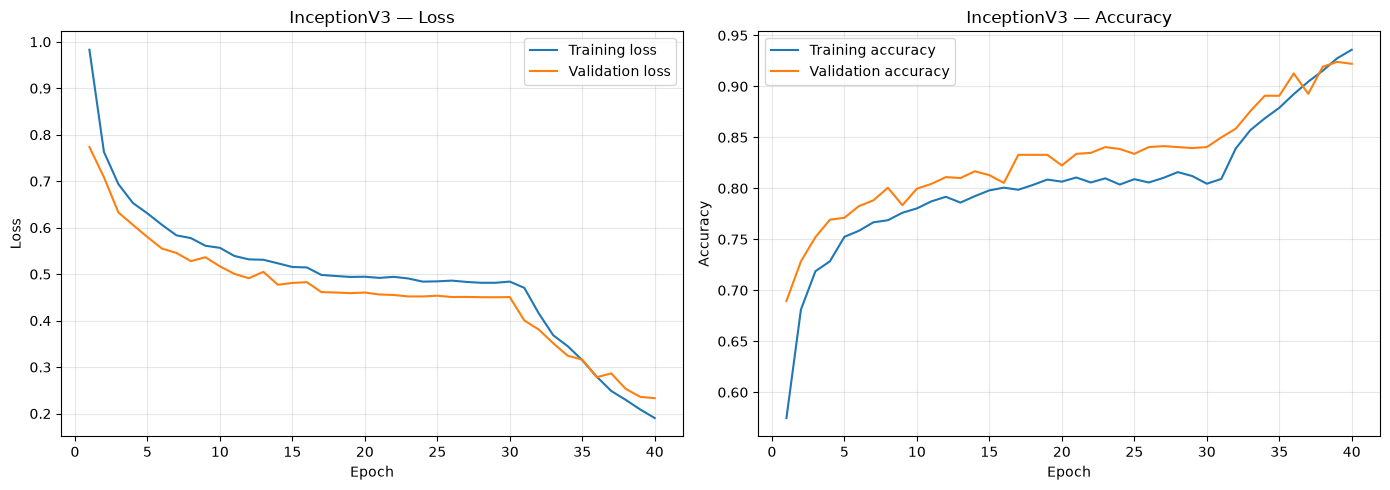

Learning curves saved to: /home/moali/projects/brainscan_ai/reports/figures/inceptionv3_training_curves.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["loss"],
    label="Training loss",
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss",
)
axes[0].set_title("InceptionV3 — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history_df["epoch"],
    history_df["accuracy"],
    label="Training accuracy",
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation accuracy",
)
axes[1].set_title("InceptionV3 — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

FIGURE_PATH = FIGURES_DIR / "inceptionv3_training_curves.png"
plt.savefig(FIGURE_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Learning curves saved to:", FIGURE_PATH)

### 13 — Save the final model

In [ ]:
if BEST_FINETUNED_MODEL_PATH.is_file():
    best_model_path = BEST_FINETUNED_MODEL_PATH
else:
    best_model_path = BEST_HEAD_MODEL_PATH

if not best_model_path.is_file():
    raise FileNotFoundError(
        "No best model checkpoint found. Complete at least the head-training phase."
    )

final_model = keras.models.load_model(
    best_model_path,
    compile=False,
)

final_model.save(FINAL_MODEL_PATH)

training_summary = {
    "architecture": "InceptionV3",
    "pretrained_weights": "ImageNet",
    "input_shape": list(INPUT_SHAPE),
    "classes": CLASS_NAMES,
    "label_to_id": LABEL_TO_ID,
    "num_classes": NUM_CLASSES,
    "selected_checkpoint": str(best_model_path),
    "final_model": str(FINAL_MODEL_PATH),
    "training_samples": int(len(train_df)),
    "validation_samples": int(len(validation_df)),
    "head_epochs_completed": int(len(head_history.epoch)),
    "history_csv": str(HISTORY_PATH),
    "random_state": int(settings.RANDOM_STATE),
}

SUMMARY_PATH = METRICS_DIR / "inceptionv3_training_summary.json"

with open(SUMMARY_PATH, "w", encoding="utf-8") as file:
    json.dump(training_summary, file, indent=4)

print("Final model saved:", FINAL_MODEL_PATH)
print("Training summary saved:", SUMMARY_PATH)

Final model saved: /home/moali/projects/brainscan_ai/models/classification/inceptionv3_final.keras
Training summary saved: /home/moali/projects/brainscan_ai/reports/metrics/inceptionv3_training_summary.json
